In [1]:
!pip install kagglehub ultralytics
import kagglehub
path = kagglehub.dataset_download('andrewmvd/hard-hat-detection')
print(path)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 9.8 MB/s eta 0:00:00


100%|██████████| 1.22G/1.22G [00:15<00:00, 83.9MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/andrewmvd/hard-hat-detection/versions/1


In [5]:
import os
import xml.etree.ElementTree as ET

ann_dir = f"{path}/annotations"
out_dir = "/content/labels"
os.makedirs(out_dir, exist_ok=True)

classes = {"helmet": 0, "head": 1}

In [12]:
file = "hard_hat_workers0.xml"
root = ET.parse(f"{ann_dir}/{file}").getroot()

w = int(root.find("size/width").text)
h = int(root.find("size/height").text)

for obj in root.findall("object"):
    name = obj.find("name").text
    if name not in classes:
        continue
    box = obj.find("bndbox")
    xmin, ymin, xmax, ymax = [float(box.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax")]

    x_center = (xmin + xmax) / 2 / w
    y_center = (ymin + ymax) / 2 / h
    box_w = (xmax - xmin) / w
    box_h = (ymax - ymin) / h

    print(classes[name], round(x_center, 3), round(y_center, 3), round(box_w, 3), round(box_h, 3))

0 0.915 0.35 0.113 0.142
0 0.052 0.397 0.084 0.091
0 0.635 0.38 0.053 0.091
0 0.749 0.392 0.055 0.087
0 0.305 0.398 0.053 0.07
0 0.216 0.398 0.048 0.07
1 0.174 0.38 0.05 0.067
1 0.802 0.383 0.055 0.089
1 0.444 0.411 0.046 0.072
1 0.555 0.4 0.043 0.075
1 0.5 0.383 0.038 0.065
0 0.252 0.361 0.034 0.048
1 0.399 0.393 0.043 0.065


In [13]:
for file in os.listdir(ann_dir):
    root = ET.parse(f"{ann_dir}/{file}").getroot()
    w = int(root.find("size/width").text)
    h = int(root.find("size/height").text)

    lines = []
    for obj in root.findall("object"):
        name = obj.find("name").text
        if name not in classes:
            continue
        box = obj.find("bndbox")
        xmin, ymin, xmax, ymax = [float(box.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax")]

        x_center = (xmin + xmax) / 2 / w
        y_center = (ymin + ymax) / 2 / h
        box_w = (xmax - xmin) / w
        box_h = (ymax - ymin) / h

        lines.append(f"{classes[name]} {x_center:.6f} {y_center:.6f} {box_w:.6f} {box_h:.6f}")

    with open(f"{out_dir}/{file.replace('.xml', '.txt')}", "w") as f:
        f.write("\n".join(lines))

print("Files created:", len(os.listdir(out_dir)))


Files created: 5000


In [14]:
import random
import shutil

names = [f.replace(".png", "") for f in os.listdir(f"{path}/images")]
random.seed(42)
random.shuffle(names)

n = len(names)
splits = {
    "train": names[:int(0.8 * n)],
    "val":   names[int(0.8 * n):int(0.9 * n)],
    "test":  names[int(0.9 * n):],
}

base = "/content/dataset"
for split, items in splits.items():
    os.makedirs(f"{base}/images/{split}", exist_ok=True)
    os.makedirs(f"{base}/labels/{split}", exist_ok=True)
    for name in items:
        shutil.copy(f"{path}/images/{name}.png", f"{base}/images/{split}/")
        shutil.copy(f"{out_dir}/{name}.txt", f"{base}/labels/{split}/")
    print(split, len(items))

train 4000
val 500
test 500


In [15]:
yaml_text = """
path: /content/dataset
train: images/train
val: images/val
test: images/test

names:
  0: helmet
  1: head
"""

with open("/content/dataset/data.yaml", "w") as f:
    f.write(yaml_text)

print(open("/content/dataset/data.yaml").read())



path: /content/dataset
train: images/train
val: images/val
test: images/test

names:
  0: helmet
  1: head



In [16]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")

model.train(
    data="/content/dataset/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fre

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79184ba96ac0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [17]:
from google.colab import drive
drive.mount("/content/drive")

!cp -r /content/runs/detect/train /content/drive/MyDrive/hard_hat_results

Mounted at /content/drive


In [18]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/hard_hat_results/weights/best.pt")
metrics = model.val(data="/content/dataset/data.yaml", split="test")


Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 61.7±36.7 MB/s, size: 288.6 KB)
val: Scanning /content/dataset/labels/test... 500 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500 303.3it/s 1.6s
val: New cache created: /content/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 3.1it/s 10.2s
                   all        500       2537      0.928      0.906      0.942      0.617
                helmet        452       1976      0.964      0.898      0.961       0.63
                  head         93        561      0.892      0.914      0.922      0.605
Speed: 1.8ms preprocess, 10.0ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val



0: 640x640 9 helmets, 13.8ms
1: 640x640 3 helmets, 13.8ms
2: 640x640 7 helmets, 13.8ms
3: 640x640 6 heads, 13.8ms
Speed: 3.7ms preprocess, 13.8ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


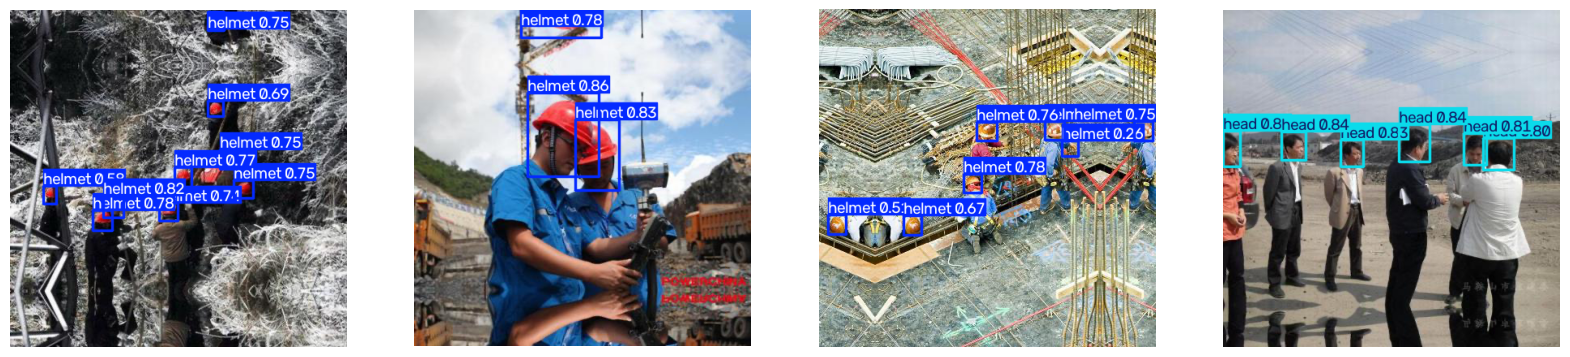

In [19]:
import glob
import matplotlib.pyplot as plt

imgs = sorted(glob.glob("/content/dataset/images/test/*.png"))[:4]
results = model.predict(imgs)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, r in zip(axes, results):
    ax.imshow(r.plot()[:, :, ::-1])
    ax.axis("off")
plt.show()

In [20]:
fig.savefig("/content/drive/MyDrive/hard_hat_results/test_predictions.png", bbox_inches="tight")
